# Loan Approval Prediction using Machine Learning

This project aims to predict whether a loan application will be approved based on applicant details such as income, credit history, and loan amount. The workflow includes data cleaning, exploratory data analysis (EDA), feature engineering, and model building using multiple machine learning algorithms. Logistic Regression achieved the best performance, and insights were derived to understand key factors influencing loan approval decisions.

## 1. Importing Libraries

In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")

## 2. Loading Dataset

In [53]:
df=pd.read_csv("loan pred.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Data Understanding

In [54]:
df.shape

(614, 13)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [56]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


## 4. Data Handling & Cleaning

In [57]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [58]:
df=df.drop("Loan_ID",axis=1)

In [59]:
for col in ["Gender", "Married", "Dependents", "Self_Employed"]:
    df[col] = df[col].fillna(df[col].mode()[0])

In [60]:
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].median())
df["Credit_History"] = df["Credit_History"].fillna(df["Credit_History"].median())

In [61]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

## 6. Exploratory Data Analysis (EDA)

### Target Distribution

<Axes: xlabel='Loan_Status', ylabel='count'>

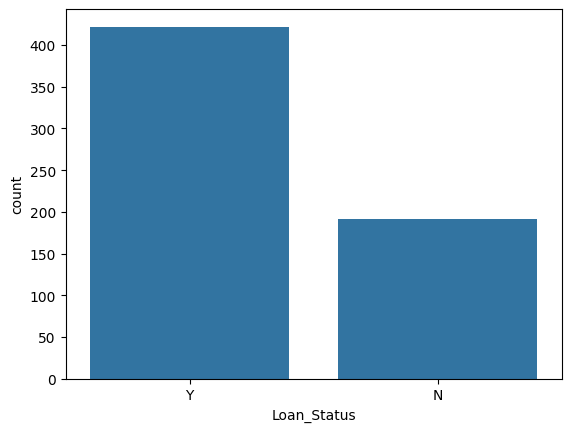

In [62]:
sns.countplot(x="Loan_Status",data =df)

### Insight
Most loan applications are approved, indicating a class imbalance where approvals dominate rejections.

## 5. Encoding

In [64]:
le=LabelEncoder()
for col in df.columns:
    if df[col].dtype=="object":
        df[col]=le.fit_transform(df[col])

### Correlation Graph

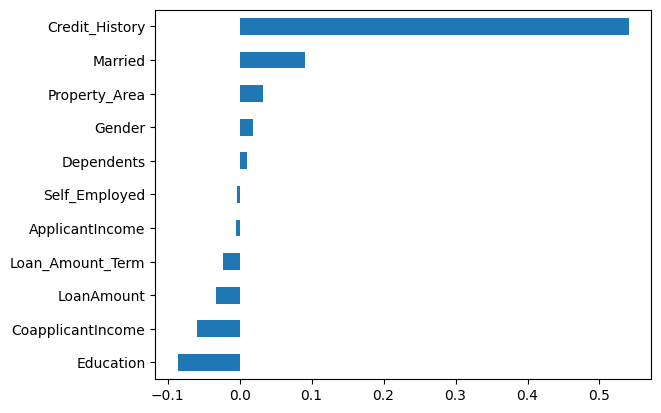

In [65]:
corr = df.corr().drop("Loan_Status")
target_corr = corr["Loan_Status"].sort_values(ascending=True)
target_corr.plot(kind="barh")
plt.show()

### Insight


### Credit History vs Loan Status

<Axes: xlabel='Credit_History', ylabel='count'>

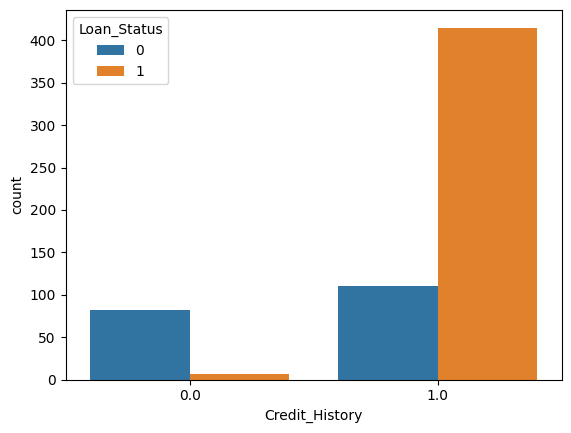

In [66]:
sns.countplot(x="Credit_History", hue="Loan_Status", data=df)

### Insight
Applicants with a credit history of 1 have a significantly higher chance of loan approval. This is the most influential feature in the dataset.

### Married vs Loan Status

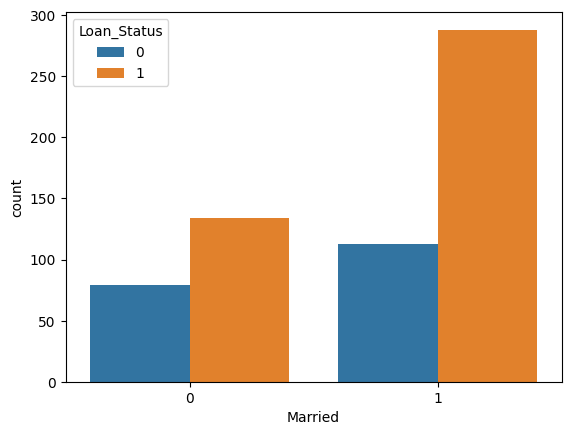

In [67]:
sns.countplot(x="Married",hue="Loan_Status",data=df)
plt.show()

### Insight
Married applicants tend to have higher loan approval rates, possibly indicating financial stability.

### Education vs Loan Status

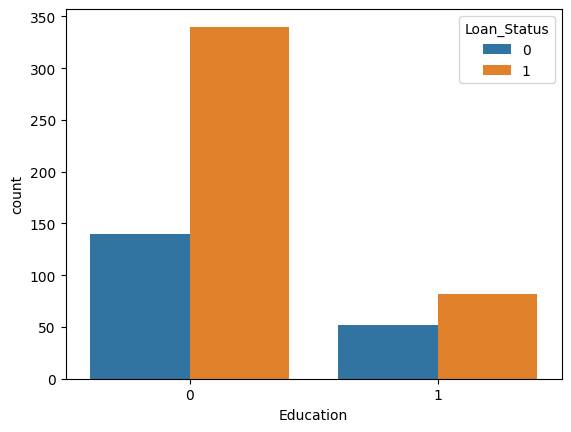

In [68]:
sns.countplot(x="Education", hue="Loan_Status", data=df)
plt.show()

### Insight
Education level shows minimal impact on loan approval, suggesting it is not a strong deciding factor.

### Property Area vs Loan

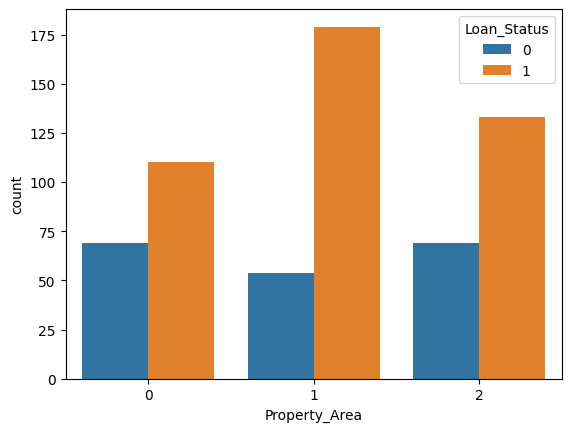

In [69]:
sns.countplot(x="Property_Area", hue="Loan_Status", data=df)
plt.show()

### Insight
Applicants from semi-urban and urban areas show slightly higher approval rates compared to rural areas.

### Coapplicant Income vs Loan Status

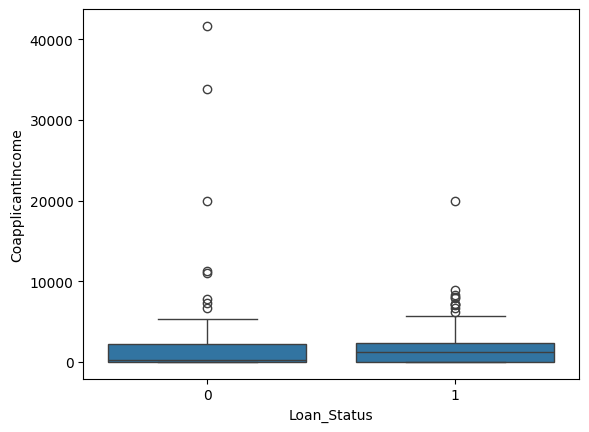

In [70]:
sns.boxplot(x="Loan_Status",y="CoapplicantIncome",data=df)
plt.show()

### Insight
Coapplicant income has very little influence on loan approval as both approved and rejected cases have similar distributions.

### Loan Amount vs Loan Status

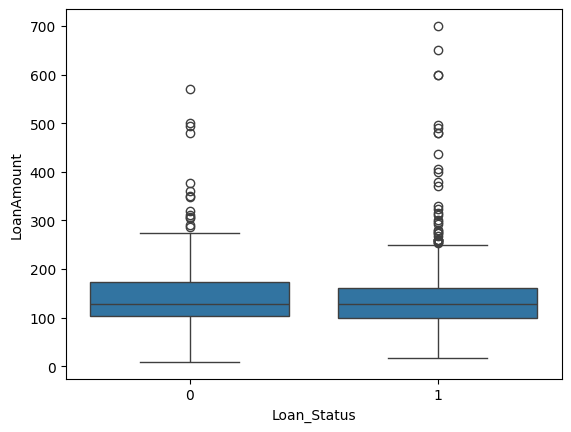

In [71]:
sns.boxplot(x="Loan_Status",y="LoanAmount",data =df)
plt.show()

### Insight
Loan amount does not significantly impact approval decisions, as distributions overlap heavily between approved and rejected cases.

## 7. Feature Engineering

In [72]:
df["Total_Income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["Loan_Income_Ratio"] = df["LoanAmount"] / df["Total_Income"]

<Axes: xlabel='Loan_Status', ylabel='Total_Income'>

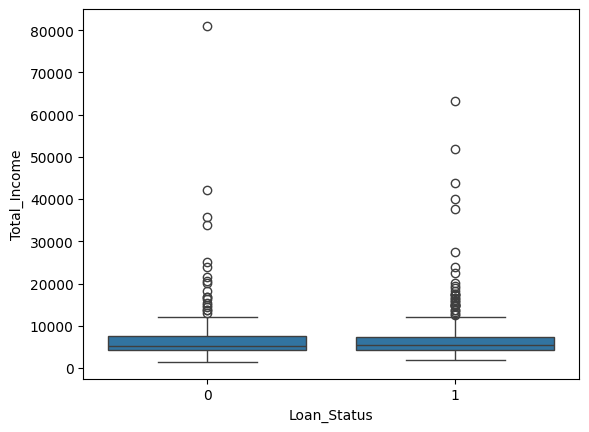

In [73]:
sns.boxplot(x="Loan_Status",y="Total_Income",data=df)

## 8. Model Building & Evaluation

In [74]:
x=df.drop("Loan_Status",axis=1)
y=df["Loan_Status"]

In [75]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [76]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [77]:
models={
    "Logistic Regression:":LogisticRegression(),
    "Decision Tree:":DecisionTreeClassifier(),
    "Random Forest:":RandomForestClassifier(n_estimators=100,random_state=42),
    "XG boost:":XGBClassifier()
}

In [78]:
for name,model in models.items():
    model.fit(x_train_scaled,y_train)
    y_pred=model.predict(x_test_scaled)
    print(name,accuracy_score(y_test,y_pred))
    print(classification_report(y_test,y_pred))
    print("f1 score:",f1_score(y_test,y_pred))

Logistic Regression: 0.7804878048780488
              precision    recall  f1-score   support

           0       0.90      0.42      0.57        43
           1       0.76      0.97      0.85        80

    accuracy                           0.78       123
   macro avg       0.83      0.70      0.71       123
weighted avg       0.81      0.78      0.75       123

f1 score: 0.8524590163934426
Decision Tree: 0.6585365853658537
              precision    recall  f1-score   support

           0       0.51      0.53      0.52        43
           1       0.74      0.72      0.73        80

    accuracy                           0.66       123
   macro avg       0.63      0.63      0.63       123
weighted avg       0.66      0.66      0.66       123

f1 score: 0.7341772151898734
Random Forest: 0.7804878048780488
              precision    recall  f1-score   support

           0       0.81      0.49      0.61        43
           1       0.77      0.94      0.85        80

    accuracy    

In [79]:
LogisticRegression(class_weight='balanced')

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [80]:
y_proba=model.predict_proba(x_test_scaled)[:,1]
y_new_proba=(y_proba > 0.6).astype(int)

## 9. Hyperparameter Tuning

In [81]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["lbfgs"]
}

grid = GridSearchCV(LogisticRegression(max_iter=1000),
                    param_grid=params,
                    cv=5,
                    scoring="f1")

grid.fit(x_train, y_train)

print("Best Params:", grid.best_params_)
print("Best Score:", grid.best_score_)

Best Params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Score: 0.87902347275156


In [82]:
best_model = grid.best_estimator_

y_pred = best_model.predict(x_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.42      0.58        43
           1       0.76      0.99      0.86        80

    accuracy                           0.79       123
   macro avg       0.85      0.70      0.72       123
weighted avg       0.83      0.79      0.76       123



## Final Conclusion

- Credit History is the most important factor in loan approval
- Income and loan amount have weak influence
- Logistic Regression performed best with highest F1 score
- Hyperparameter tuning did not significantly improve performance
- The dataset is relatively simple, so simpler models perform better

This model can help banks quickly identify eligible loan applicants.